## Import

In [1]:
import json, os, time, pickle, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, average_precision_score, mean_squared_error, mean_absolute_error, r2_score)
warnings.filterwarnings("ignore")
torch.set_num_threads(1)

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Setup

In [2]:
SEED = 42
N_TRIALS = 30
INNER_K = 3
K = 5                    # repeat 1 of the shared folds
FRACS = [0.25, 0.5, 0.75, 1.0]   # share of each outer training fold that is kept
np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs("weights_V7_1", exist_ok=True); os.makedirs("media", exist_ok=True)

In [3]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
print("cleaned:", df.shape, "| Response rate:", round(df["Response"].mean(), 4))

CLF_NUMERIC = ["AcceptedCmp5","AcceptedCmp3","MntWines","MntMeatProducts","NumCatalogPurchases",
    "Recency","Customer_Tenure_Days","MntGoldProds","Income","MntFruits","AcceptedCmp1",
    "AcceptedCmp2","NumWebPurchases","MntSweetProducts","MntFishProducts","NumStorePurchases","Age"]
X_num = df[CLF_NUMERIC].copy()
X_cat = pd.get_dummies(df[["Marital_Status"]], dtype=float)
X_full = pd.concat([X_num, X_cat], axis=1)
FEATURE_COLS = list(X_full.columns)
y_full = df["Response"].astype(float).values
print(f"features: {len(CLF_NUMERIC)} numeric + {X_cat.shape[1]} dummies = {len(FEATURE_COLS)} dims")

cleaned: (2236, 28) | Response rate: 0.1494
features: 17 numeric + 5 dummies = 22 dims


In [4]:
# Feature interaction hand-off (Feature Interaction section of classify.ipynb):
# the strongest interacting features (Teenhome, NumDealsPurchases, NumWebVisitsMonth) are not in the 22-dim model set.
EXTRA = ["Teenhome", "NumDealsPurchases", "NumWebVisitsMonth"]
X_full = pd.concat([X_full, df[EXTRA].astype(float)], axis=1)
ALL_COLS = list(X_full.columns)
BASE_COLS = ALL_COLS[:len(FEATURE_COLS)]
X_all = X_full.values
y_all = y_full.astype(int)

def top_pairs(csv_path, cols, k):
    """Top-k significant (q < 0.05) pairs by effect size where both features are in `cols`."""
    t = pd.read_csv(csv_path)
    t = t[(t.q < 0.05) & t.A.isin(cols) & t.B.isin(cols)].sort_values("effect", ascending=False)
    return list(zip(t.A.head(k), t.B.head(k)))

PAIRS = top_pairs("results/interaction_clf.csv", BASE_COLS + EXTRA, 5)
print("pair features:", PAIRS)
SETS = {
    "base (22)":                  dict(cols=BASE_COLS, pairs=[]),
    "+ 3 modifiers (25)":         dict(cols=BASE_COLS + EXTRA, pairs=[]),
    "+ 3 modifiers + 5 pairs":    dict(cols=BASE_COLS + EXTRA, pairs=PAIRS),
}
inc_name = "Income"

def prep_split(tr_idx, te_idx, set_name):
    """Median-fill Income, standardise, then append standardised products for the pair features (training rows only)."""
    cols, pairs = SETS[set_name]["cols"], SETS[set_name]["pairs"]
    ci = [ALL_COLS.index(c) for c in cols]
    A, B = X_all[tr_idx][:, ci].copy(), X_all[te_idx][:, ci].copy()
    j = cols.index(inc_name); med = np.nanmedian(A[:, j])
    for a in (A, B):
        a[:, j] = np.where(np.isnan(a[:, j]), med, a[:, j])
    sc = StandardScaler().fit(A); A, B = sc.transform(A), sc.transform(B)
    if pairs:
        ix = {c: i for i, c in enumerate(cols)}
        PA = np.column_stack([A[:, ix[a]] * A[:, ix[b]] for a, b in pairs])
        PB = np.column_stack([B[:, ix[a]] * B[:, ix[b]] for a, b in pairs])
        sp = StandardScaler().fit(PA); A, B = np.hstack([A, sp.transform(PA)]), np.hstack([B, sp.transform(PB)])
    return A, B, y_all[tr_idx], y_all[te_idx]

idx_all = np.arange(len(y_all))
tr_idx, te_idx = train_test_split(idx_all, test_size=0.20, random_state=SEED, stratify=y_all)
for s_ in SETS:
    a_, b_, _, _ = prep_split(tr_idx, te_idx, s_)
    print(f"{s_:26s} train {a_.shape} test {b_.shape}")

pair features: [('Teenhome', 'NumWebVisitsMonth'), ('NumDealsPurchases', 'NumStorePurchases'), ('Income', 'NumDealsPurchases'), ('NumDealsPurchases', 'NumWebVisitsMonth'), ('MntSweetProducts', 'NumStorePurchases')]
base (22)                  train (1788, 22) test (448, 22)
+ 3 modifiers (25)         train (1788, 25) test (448, 25)
+ 3 modifiers + 5 pairs    train (1788, 30) test (448, 30)


## Model

In [5]:
EPOCHS_MAX, BATCH, LR, WD = 100, 64, 1e-3, 1e-4     # same optimiser settings as V2_0
device = torch.device("cpu")

def run_epochs(model, X, y, loss_fn, epochs, seed, on_epoch=None):
    """Adam + cosine (T_max = 100), mini-batch 64. on_epoch(epoch, model) is called after every epoch."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999), eps=1e-8, weight_decay=WD)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_MAX)
    Xt = torch.from_numpy(np.asarray(X, dtype=np.float32)); yt = torch.from_numpy(np.asarray(y, dtype=np.float32)).view(-1, 1)
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt), generator=g)
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad(); loss_fn(model(Xt[idx]), yt[idx]).backward(); opt.step()
        sch.step()
        if on_epoch is not None:
            on_epoch(ep, model)
    return model

def smooth(a, w=5):
    return np.convolve(np.pad(a, (w // 2, w // 2), mode="edge"), np.ones(w) / w, mode="valid")

def n_params(m):
    return int(sum(p.numel() for p in m.parameters()))

In [6]:
class TransformerBlock(nn.Module):
    """Pre-norm block. ffn='relu': Linear(d,hid) -> ReLU -> Linear(hid,d).
       ffn='reglu': Linear(d,2*hid) split into (value, gate) -> value * ReLU(gate) -> Linear(hid,d)."""
    def __init__(self, d=32, h=4, p=0.1, ffn="relu", hid=None):
        super().__init__()
        assert d % h == 0; self.h, self.dk, self.ffn = h, d // h, ffn
        hid = hid or 2 * d
        self.ln1 = nn.LayerNorm(d, eps=1e-5); self.ln2 = nn.LayerNorm(d, eps=1e-5)
        self.wq = nn.Linear(d, d); self.wk = nn.Linear(d, d); self.wv = nn.Linear(d, d); self.wo = nn.Linear(d, d)
        self.fc1 = nn.Linear(d, hid if ffn == "relu" else 2 * hid); self.fc2 = nn.Linear(hid, d)
        self.relu = nn.ReLU(); self.drop = nn.Dropout(p); self.attn_drop = nn.Dropout(p)
        for fc in (self.wq, self.wk, self.wv, self.wo, self.fc1, self.fc2):
            nn.init.kaiming_normal_(fc.weight, nonlinearity="relu"); nn.init.zeros_(fc.bias)
    def forward(self, t):
        B, T, D = t.shape
        h_in = self.ln1(t)
        Q = self.wq(h_in).view(B, T, self.h, self.dk).transpose(1, 2)
        K = self.wk(h_in).view(B, T, self.h, self.dk).transpose(1, 2)
        V = self.wv(h_in).view(B, T, self.h, self.dk).transpose(1, 2)
        s = (Q @ K.transpose(-2, -1)) / (self.dk ** 0.5)
        p = self.attn_drop(torch.softmax(s, dim=-1))
        o = (p @ V).transpose(1, 2).reshape(B, T, D)
        u = t + self.wo(o)
        z = self.fc1(self.ln2(u))
        if self.ffn == "reglu":
            val, gate = z.chunk(2, dim=-1); a = val * self.relu(gate)
        else:
            a = self.relu(z)
        return u + self.fc2(self.drop(a))

class FTTransformerLite(nn.Module):
    def __init__(self, in_dim=22, d=32, layers=2, heads=4, p=0.1, ffn="relu", hid=None):
        super().__init__()
        # tokenizer: feature j has its own Linear(1 -> d). Stored as two tables (in_dim x d) so all
        # features are embedded in one operation; the maths is identical to in_dim separate Linear(1, d).
        self.tok_w = nn.Parameter(torch.randn(in_dim, d) * (2.0 ** 0.5))   # He init, fan_in = 1
        self.tok_b = nn.Parameter(torch.zeros(in_dim, d))
        self.cls = nn.Parameter(torch.randn(d) * 0.02)
        self.blocks = nn.ModuleList([TransformerBlock(d, heads, p, ffn, hid) for _ in range(layers)])
        self.ln_f = nn.LayerNorm(d, eps=1e-5)
        self.head = nn.Linear(d, 1)
        nn.init.kaiming_normal_(self.head.weight, nonlinearity="linear"); nn.init.zeros_(self.head.bias)
    def forward(self, x):
        B = x.shape[0]
        t = x.unsqueeze(-1) * self.tok_w + self.tok_b                       # (B, in_dim, d)
        t = torch.cat([self.cls.view(1, 1, -1).expand(B, 1, -1), t], dim=1)
        for blk in self.blocks:
            t = blk(t)
        return self.head(self.ln_f(t[:, 0]))

# hidden size 64 = 2d is the ReLU baseline. ReGLU "same hidden" keeps 64 (more parameters);
# ReGLU "param-matched" uses hidden = 4/3 d = 43 (the original paper's factor) to land on the ReLU parameter count.
VARIANTS = {
    "ReLU (baseline)":       dict(ffn="relu", hid=64),
    "ReGLU, same hidden":    dict(ffn="reglu", hid=64),
    "ReGLU, param-matched":  dict(ffn="reglu", hid=43),
}
def make_model(v, seed, in_dim=None):
    torch.manual_seed(seed)
    return FTTransformerLite(in_dim=in_dim or len(FEATURE_COLS), **VARIANTS[v]).to(device)

In [7]:
import lightgbm as lgb
POS_W = float((y_all == 0).sum() / (y_all == 1).sum())  # class ratio, one scalar
SPECS = {
 "LightGBM": dict(tier="curriculum", kind="proba",
    space=lambda t: dict(n=t.suggest_int("n", 100, 600, step=100), lr=t.suggest_float("lr", 0.01, 0.3, log=True),
                         nl=t.suggest_int("nl", 4, 64), mcs=t.suggest_int("mcs", 5, 50),
                         sub=t.suggest_float("sub", 0.6, 1.0), col=t.suggest_float("col", 0.5, 1.0),
                         lam=t.suggest_float("lam", 1e-2, 10, log=True), spw=t.suggest_categorical("spw", [1.0, POS_W])),
    make=lambda p, s: lgb.LGBMClassifier(n_estimators=p["n"], learning_rate=p["lr"], num_leaves=p["nl"],
                         min_child_samples=p["mcs"], subsample=p["sub"], subsample_freq=1, colsample_bytree=p["col"],
                         reg_lambda=p["lam"], scale_pos_weight=p["spw"], n_jobs=1, random_state=s, verbosity=-1)),
}

In [8]:
def score_of(est, X, kind):
    return est.predict_proba(X)[:, 1] if kind == "proba" else est.decision_function(X)

def inner_oof(spec, params, X, y, seed):
    """Out-of-fold scores on the training rows (inner K-fold)."""
    oof = np.zeros(len(y))
    for a, b in StratifiedKFold(INNER_K, shuffle=True, random_state=seed).split(X, y):
        est = spec["make"](params, seed)
        est.fit(X[a], y[a])
        oof[b] = score_of(est, X[b], spec["kind"])
    return oof

def tune(spec, X, y, seed):
    """Optuna (TPE) maximising average precision of the inner out-of-fold scores."""
    def objective(trial):
        return average_precision_score(y, inner_oof(spec, spec["space"](trial), X, y, seed))
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=spec.get("trials", N_TRIALS))
    return spec["space"](optuna.trial.FixedTrial(study.best_params))

def best_threshold(y, s):
    """F1-maximising threshold, searched on training-side out-of-fold scores only."""
    cand = np.unique(np.quantile(s, np.linspace(0.40, 0.99, 120)))
    f = [f1_score(y, (s >= t).astype(int), zero_division=0) for t in cand]
    return float(cand[int(np.argmax(f))])

def fit_eval(spec, params, Xa, ya, Xb, yb, seed):
    """Threshold from inner OOF on (Xa, ya); refit on all of (Xa, ya); score (Xb, yb)."""
    thr = best_threshold(ya, inner_oof(spec, params, Xa, ya, seed))
    est = spec["make"](params, seed)
    est.fit(Xa, ya)
    s = score_of(est, Xb, spec["kind"])
    pred = (s >= thr).astype(int)
    row = {"f1": f1_score(yb, pred, zero_division=0), "accuracy": accuracy_score(yb, pred),
           "precision": precision_score(yb, pred, zero_division=0),
           "recall": recall_score(yb, pred, zero_division=0),
           "roc_auc": roc_auc_score(yb, s), "threshold": thr}
    if spec["kind"] == "proba":
        row["bce"] = log_loss(yb, np.clip(s, 1e-12, 1 - 1e-12))
    return row, s

lgb_fit_eval = fit_eval

In [9]:
INNER_K = 3
EPOCHS_INNER = 40    # the cosine schedule still spans 100 epochs; selected epochs were far below 40 in V2_0 runs
def best_threshold(y, s):
    """F1-maximising threshold, searched on training-side out-of-fold scores only."""
    cand = np.unique(np.quantile(s, np.linspace(0.40, 0.99, 120)))
    f = [f1_score(y, (s >= t).astype(int), zero_division=0) for t in cand]
    return float(cand[int(np.argmax(f))])

def scores_of(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(np.asarray(X, dtype=np.float32)))).numpy().ravel()

def fit_eval(variant, Xa, ya, Xb, yb, seed):
    """Epoch count and threshold come from an inner K-fold on (Xa, ya) only; (Xb, yb) is scored once."""
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([float((ya == 0).sum() / (ya == 1).sum())]))
    inner = []
    for k, (a, b) in enumerate(StratifiedKFold(INNER_K, shuffle=True, random_state=seed).split(Xa, ya)):
        store = []
        run_epochs(make_model(variant, seed + k, Xa.shape[1]), Xa[a], ya[a], loss_fn, EPOCHS_INNER, seed + k,
                   on_epoch=lambda ep, m, b=b: store.append(scores_of(m, Xa[b])))
        inner.append((b, np.array(store)))
    ap = np.mean([[average_precision_score(ya[b], sc[e]) for e in range(EPOCHS_INNER)] for b, sc in inner], axis=0)
    E = int(np.argmax(smooth(ap))) + 1                       # epoch chosen on inner validation only
    oof = np.zeros(len(ya))
    for b, sc in inner:
        oof[b] = sc[E - 1]
    thr = best_threshold(ya, oof)
    model = run_epochs(make_model(variant, seed + 99, Xa.shape[1]), Xa, ya, loss_fn, E, seed + 99)
    s = scores_of(model, Xb)
    pred = (s >= thr).astype(int)
    row = {"f1": f1_score(yb, pred, zero_division=0), "accuracy": accuracy_score(yb, pred),
           "precision": precision_score(yb, pred, zero_division=0), "recall": recall_score(yb, pred, zero_division=0),
           "roc_auc": roc_auc_score(yb, s), "bce": log_loss(yb, np.clip(s, 1e-12, 1 - 1e-12)),
           "threshold": thr, "epochs": E, "n_params": n_params(model)}
    return row, s

nn_fit_eval = fit_eval

## Training

In [10]:
cache = "weights_V7_1/_progress_classification_pytorch_lc.pkl"
rows = pickle.load(open(cache, "rb")) if os.path.exists(cache) else []
done = {(r["model"], r["frac"], r["fold"]) for r in rows}
spec = SPECS["LightGBM"]
for fold, (a_full, b) in enumerate(StratifiedKFold(K, shuffle=True, random_state=SEED).split(X_all, y_all), start=1):
    for frac in FRACS:
        sd = SEED * 100 + fold
        a = a_full
        a = train_test_split(a, train_size=frac, stratify=y_all[a], random_state=sd)[0] if frac < 1 else a                     # the same smaller training set for both models
        for name, sname in (("FT-Transformer-lite | + 3 modifiers + 5 pairs", "+ 3 modifiers + 5 pairs"), ("LightGBM | + 3 modifiers + 5 pairs", "+ 3 modifiers + 5 pairs")):
            if (name, frac, fold) in done:
                continue
            Xa, Xb, ya, yb = prep_split(a, b, sname)
            t0 = time.time()
            if name.startswith("LightGBM"):
                params = tune(spec, Xa, ya, sd)
                row, _ = lgb_fit_eval(spec, params, Xa, ya, Xb, yb, sd)
            else:
                row, _ = nn_fit_eval("ReLU (baseline)", Xa, ya, Xb, yb, sd)
            rows.append(dict(model=name, frac=frac, n_train=int(len(a)), fold=fold, f1=round(float(row["f1"]), 4),
                             seconds=round(time.time() - t0, 1)))
            pickle.dump(rows, open(cache, "wb"))
            print(f"fold {fold} frac {frac:.2f} n={len(a)} {name:45s} F1 {row['f1']:.4f}", flush=True)

fold 1 frac 0.25 n=447 FT-Transformer-lite | + 3 modifiers + 5 pairs F1 0.5954


fold 1 frac 0.25 n=447 LightGBM | + 3 modifiers + 5 pairs            F1 0.5875


fold 1 frac 0.50 n=894 FT-Transformer-lite | + 3 modifiers + 5 pairs F1 0.6111


fold 1 frac 0.50 n=894 LightGBM | + 3 modifiers + 5 pairs            F1 0.6061


fold 1 frac 0.75 n=1341 FT-Transformer-lite | + 3 modifiers + 5 pairs F1 0.6012


...

fold 5 frac 0.50 n=894 LightGBM | + 3 modifiers + 5 pairs            F1 0.5476


fold 5 frac 0.75 n=1341 FT-Transformer-lite | + 3 modifiers + 5 pairs F1 0.4882


fold 5 frac 0.75 n=1341 LightGBM | + 3 modifiers + 5 pairs            F1 0.5736


fold 5 frac 1.00 n=1789 FT-Transformer-lite | + 3 modifiers + 5 pairs F1 0.5405


fold 5 frac 1.00 n=1789 LightGBM | + 3 modifiers + 5 pairs            F1 0.5891


## Evaluation

                                        model  frac  n_train   mean    std
FT-Transformer-lite | + 3 modifiers + 5 pairs  0.25    447.0 0.4658 0.0942
FT-Transformer-lite | + 3 modifiers + 5 pairs  0.50    894.0 0.5054 0.0780
FT-Transformer-lite | + 3 modifiers + 5 pairs  0.75   1341.0 0.5304 0.0435
FT-Transformer-lite | + 3 modifiers + 5 pairs  1.00   1788.8 0.5635 0.0315
           LightGBM | + 3 modifiers + 5 pairs  0.25    447.0 0.5342 0.0315
           LightGBM | + 3 modifiers + 5 pairs  0.50    894.0 0.5640 0.0415
           LightGBM | + 3 modifiers + 5 pairs  0.75   1341.0 0.5727 0.0401
           LightGBM | + 3 modifiers + 5 pairs  1.00   1788.8 0.5976 0.0581

gap (LightGBM minus FT-Transformer-lite) by training share:
        mean     std
frac                
0.25  0.0684  0.0750
0.50  0.0586  0.0517
0.75  0.0423  0.0530
1.00  0.0341  0.0630


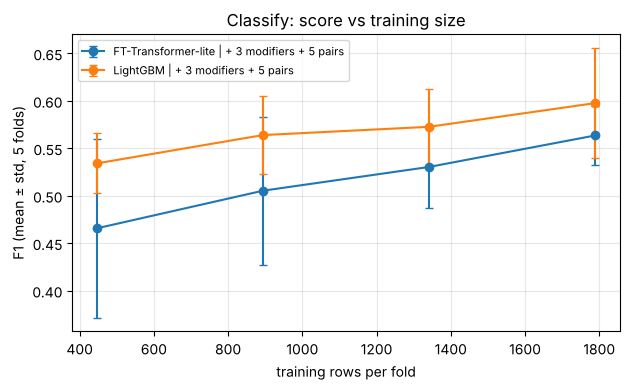

In [11]:
import matplotlib.pyplot as plt
lc = pd.DataFrame(rows)
tab = lc.groupby(["model", "frac"]).agg(n_train=("n_train", "mean"), mean=("f1", "mean"), std=("f1", "std")).reset_index()
wide = lc.pivot_table(index=["frac", "fold"], columns="model", values="f1")
nn_col = [c for c in wide.columns if not c.startswith("LightGBM")][0]; lgb_col = [c for c in wide.columns if c.startswith("LightGBM")][0]
gap = (wide[lgb_col] - wide[nn_col]).groupby(level=0).agg(["mean", "std"])
print(tab.round(4).to_string(index=False)); print("\ngap (LightGBM minus FT-Transformer-lite) by training share:"); print(gap.round(4).to_string())
json.dump({"k": K, "fracs": FRACS, "rows": rows, "gap": gap.reset_index().to_dict("records")},
          open("weights_V7_1/classification_pytorch_learning_curve.json", "w"), indent=2)
fig, ax = plt.subplots(figsize=(6.4, 4))
for m, g in tab.groupby("model"):
    ax.errorbar(g["n_train"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=m)
ax.set_xlabel("training rows per fold"); ax.set_ylabel("F1 (mean ± std, 5 folds)")
ax.set_title("Classify: score vs training size"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("media/learncurve_clf_V7_1.png", dpi=160); plt.show()